# Who Scores in Europe's Top 5 Leagues? Football Player Stats 2021-2022
**CMSC 320 Final Project Checkpoint 2**

## Contributions
| Name | Contribution |
|---|---|
| Marco Sinobad | _ |
| Rahul Manchanda-Izquierdo | Introduction, distribution & outliers, and proofreading |
| William Schmelyun | _ |
| Oisin Dobbie | _ |
| Samuel Walls | Data import, parsing, cleaning, and describing |
| Vahe Zaprozyan | _ |

## Introduction
Football (soccer) clubs spend millions of dollars on players, so it matters to know which stats really relate to scoring and how players differ by position and age. In this checkpoint we explore player stats from the Big 5 European leagues for the 2021-2022 season. We ask three questions:

1. Which stats are most strongly linked to the number of goals a player scores?
2. Do forwards, midfielders, and defenders really score at different rates?
3. Do young players (23 and under) and veteran players (30 and over) produce goals and assists at different rates?

**Data source:** [2021-2022 Football Player Stats (Kaggle, vivovinco)](https://www.kaggle.com/datasets/vivovinco/20212022-football-player-stats/data). The stats come from FBref. Download the CSV and put it in the same folder as this notebook.

## Data Preprocessing
### Import libraries

In [201]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn

seaborn.set_theme(style="darkgrid", palette="colorblind", context="notebook")

### Import Dataset
The file uses semicolons instead of commas, so we set read_csv to separate by semicolons. UTF-8 encoding didn't work because of some special characters so latin-1 encoding was used instead.

In [202]:
DATA_PATH = "2021-2022 Football Player Stats.csv"
df = pd.read_csv(DATA_PATH, sep=";", encoding='latin-1')

print(f"Number of entries (players): {df.shape[0]}")
print(f"Number of features: {df.shape[1]}")
df.head()

Number of entries (players): 2921
Number of features: 143


,Rk,Player,Nation,Pos,Squad,Comp,Age,Born,MP,Starts,...,Off,Crs,TklW,PKwon,PKcon,OG,Recov,AerWon,AerLost,AerWon%
0,1,Max Aarons,ENG,DF,Norwich City,Premier League,22.0,2000,34,32,...,0.03,1.41,1.16,0.0,0.06,0.03,5.53,0.47,1.59,22.7
1,2,Yunis Abdelhamid,MAR,DF,Reims,Ligue 1,34.0,1987,34,34,...,0.00,0.06,1.39,0.0,0.03,0.00,6.77,2.02,1.36,59.8
2,3,Salis Abdul Samed,GHA,MF,Clermont Foot,Ligue 1,22.0,2000,31,29,...,0.00,0.36,1.24,0.0,0.00,0.00,8.76,0.88,0.88,50.0
3,4,Laurent Abergel,FRA,MF,Lorient,Ligue 1,29.0,1993,34,34,...,0.03,0.79,2.23,0.0,0.00,0.00,8.87,0.43,0.43,50.0
4,5,Charles Abi,FRA,FW,Saint-Étienne,Ligue 1,22.0,2000,1,1,...,0.00,2.00,0.00,0.0,0.00,0.00,4.00,2.00,0.00,100.0


### Parse Data
Fix the position column and only display the columns relevant to our project.

In [203]:
df.columns = df.columns.str.strip()
# Only include first listed position
df["Primary_Position"] = df["Pos"].astype(str).str[0:2]

# Make sure number columns are actually numbers
num_cols = ["Age", "Born", "MP", "Starts", "Min", "90s", "Goals", "Shots", "SoT",
            "Assists", "Tkl", "Int", "Fls", "CrdY", "CrdR", "Recov", "AerWon"]

df[["Player", "Nation", "Primary_Position", "Squad", "Comp", "Age", "Min", "Goals", "Assists"]].head()

,Player,Nation,Primary_Position,Squad,Comp,Age,Min,Goals,Assists
0,Max Aarons,ENG,DF,Norwich City,Premier League,22.0,2881,0.00,0.06
1,Yunis Abdelhamid,MAR,DF,Reims,Ligue 1,34.0,2983,0.06,0.00
2,Salis Abdul Samed,GHA,MF,Clermont Foot,Ligue 1,22.0,2462,0.04,0.00
3,Laurent Abergel,FRA,MF,Lorient,Ligue 1,29.0,2956,0.00,0.06
4,Charles Abi,FRA,FW,Saint-Étienne,Ligue 1,22.0,45,0.00,0.00


### Clean Data
Handle missing values in the dataset and remove players who do not have sufficient playing time.

In [204]:
# Drop rows with no playing time info, fill any null values with with the mean value in the column
df = df.dropna(subset=["90s"])
df[num_cols] = df[num_cols].fillna(df[num_cols].mean())

# Only consider players have at least 10 full matches worth of minutes
df = df[df["90s"] >= 10]

## Dataset characteristics
Before testing anything, we look at the size of the data, which groups are over-represented, and how stats are spread out.

In [214]:
df[["Age", "Min", "Goals", "Assists", "Shots", "Tkl", "Int", "Fls"]].describe().round(2)

,Age,Min,Goals,Assists,Shots,Tkl,Int,Fls
count,1641.00,1641.00,1641.00,1641.00,1641.00,1641.00,1641.00,1641.00
mean,27.01,1959.12,0.13,0.09,1.15,1.65,1.42,1.26
std,4.11,667.27,0.16,0.10,0.92,0.90,0.84,0.67
min,17.00,896.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,24.00,1397.00,0.00,0.00,0.44,1.06,0.77,0.83
50%,27.00,1890.00,0.06,0.06,0.87,1.64,1.45,1.25
75%,30.00,2495.00,0.18,0.14,1.76,2.25,2.00,1.68
max,40.00,3420.00,1.07,0.83,4.80,4.43,5.22,3.99


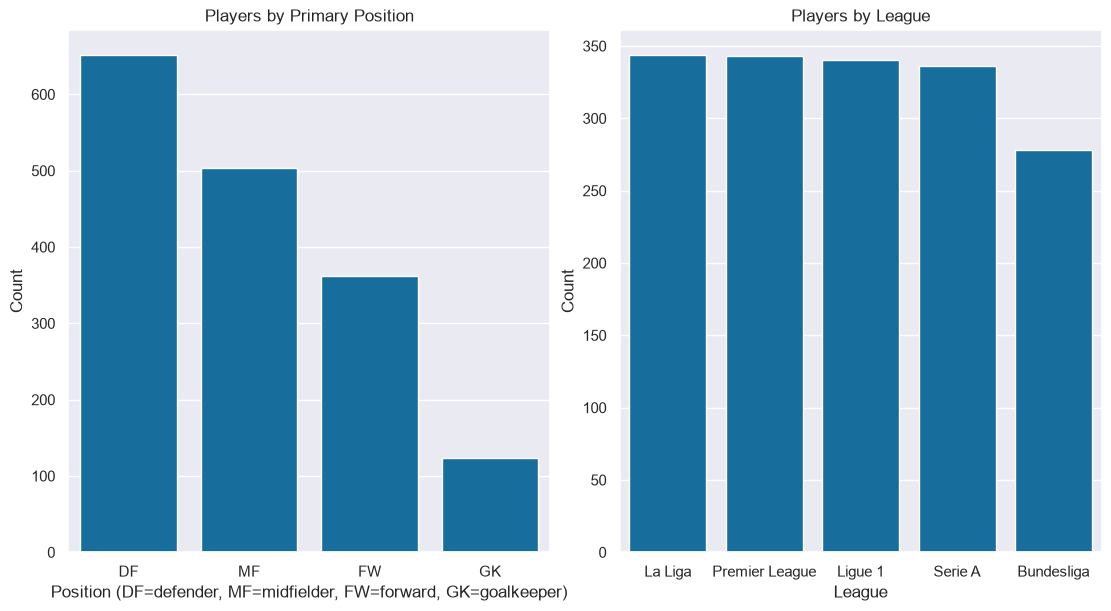

In [206]:
seaborn.set_theme(style="darkgrid", palette="colorblind")
fig, axes = plt.subplots(1, 2, constrained_layout=True)

positions_order = df["Primary_Position"].value_counts().index
seaborn.countplot(data=df, x="Primary_Position", order=positions_order, ax=axes[0])
axes[0].set_title("Players by Primary Position")
axes[0].set_xlabel("Position (DF=defender, MF=midfielder, FW=forward, GK=goalkeeper)")
axes[0].set_ylabel("Count")

league_order = df["Comp"].value_counts().index
seaborn.countplot(data=df, x="Comp", order=league_order, ax=axes[1])
axes[1].set_title("Players by League")
axes[1].set_ylabel("Count")
axes[1].set_xlabel("League")
plt.show()

Defenders and midfielders make up most of the data, and goalkeepers are a small group. Leagues are fairly balanced. Because goalkeepers are safely classified as non-scorers, we leave them out of the goal-scoring tests later.

### Distribution and Outliers
Goals are a count that is bunched near zero, so we expect a strong right skew.

In [228]:
goals = df["Goals"]
q1, q3 = goals.quantile([0.25, 0.75])
iqr = q3 - q1
upper = q3 + 1.5 * iqr
outliers = df[goals > upper]

print(f"There are {len(outliers)} Outliers")
print("\nTop 10 scorers:")
df.nlargest(10, "Goals")[["Player", "Squad", "Comp", "Primary_Position", "Goals", "Min"]]

There are 89 Outliers

Top 10 scorers:


,Player,Squad,Comp,Primary_Position,Goals,Min
1512,Robert Lewandowski,Bayern Munich,Bundesliga,FW,1.07,2946
1117,Erling Haaland,Dortmund,Bundesliga,FW,1.04,1911
2425,Patrik Schick,Leverkusen,Bundesliga,FW,1.04,2076
284,Karim Benzema,Real Madrid,La Liga,FW,0.94,2593
140,Pierre-Emerick Aubameyang,Barcelona,La Liga,FW,0.92,1082
1236,Ciro Immobile,Lazio,Serie A,FW,0.90,2711
265,Wissam Ben Yedder,Monaco,Ligue 1,FW,0.89,2529
668,Moussa Dembélé,Lyon,Ligue 1,FW,0.86,2207
1689,Lautaro Martínez,Inter,Serie A,FW,0.83,2282
1720,Kylian Mbappé,Paris S-G,Ligue 1,FW,0.83,3023


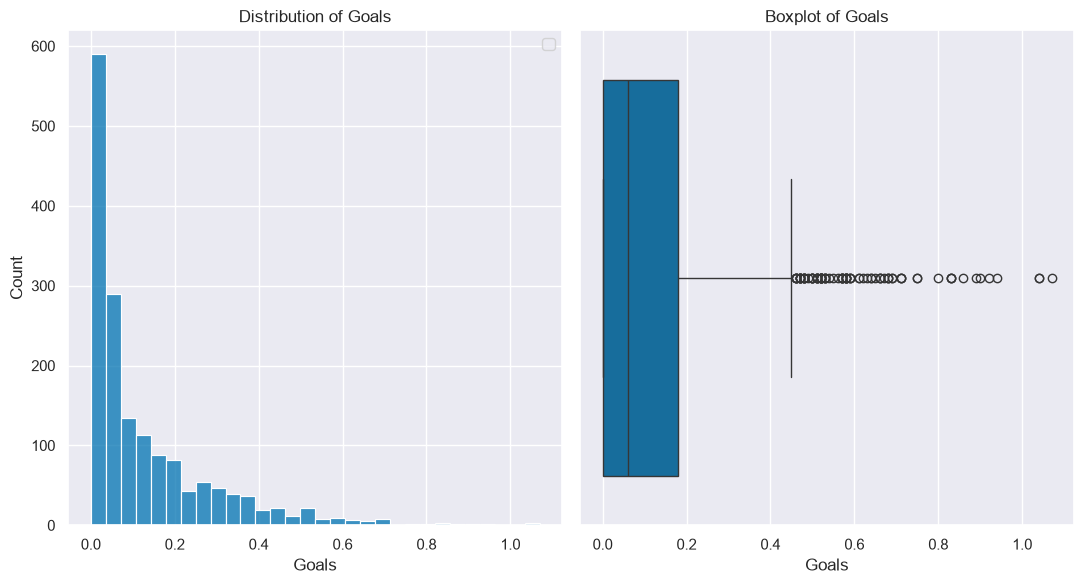

In [224]:
fig, axes = plt.subplots(1, 2)

seaborn.histplot(df["Goals"], bins=30, kde=False, ax=axes[0])
axes[0].set_title("Distribution of Goals")
axes[0].legend()

seaborn.boxplot(x=df["Goals"], ax=axes[1])
axes[1].set_title("Boxplot of Goals")
plt.tight_layout()
plt.show()

Goals are strongly right-skewed. A few good players score far more than everyone else, and these show up as outliers. We keep them because they are real players and not data errors. Since the data is not normal, we will use tests that do not assume normality like Spearman, Kruskal-Wallis and Mann-Whitney.

## Analysis 1: Which stats go with goals? (Correlation)
**Method:** Pearson and Spearman correlation.

**Question:** Which stats are most strongly related to goals scored?

**H0:** There is no linear relationship between shots and goals (correlation = 0).
**H1:** There is a relationship (correlation is not 0).

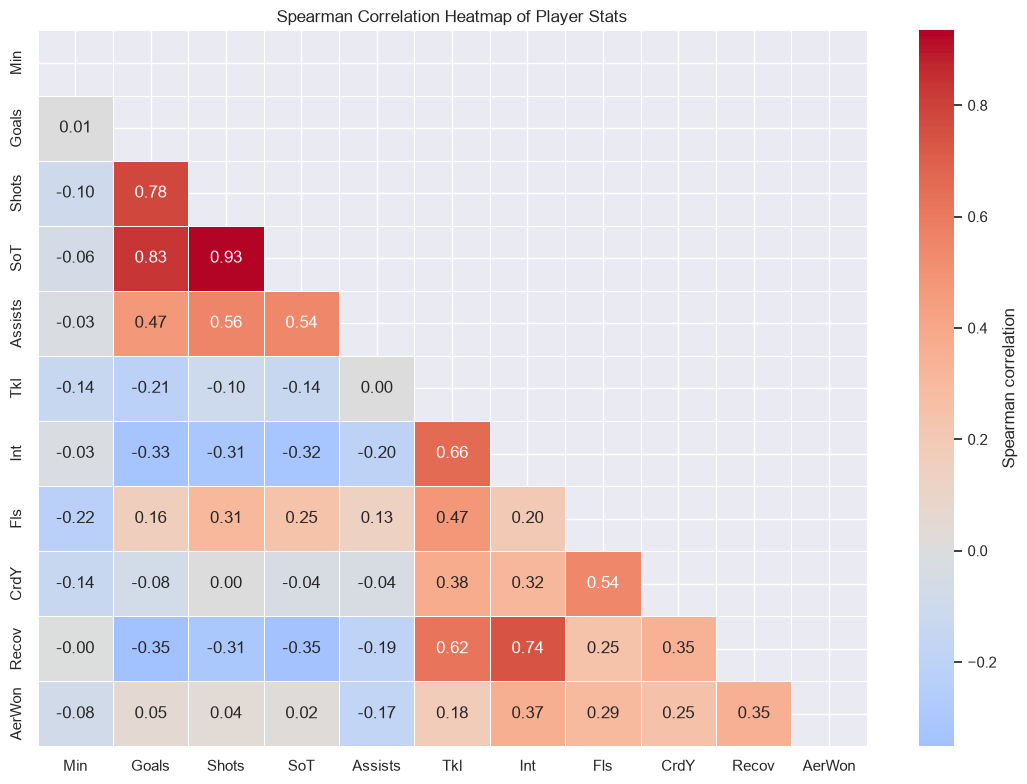

Correlation with Goals (Spearman):
SoT        0.833
Shots      0.781
Assists    0.471
Fls        0.158
AerWon     0.051
Min        0.009
CrdY      -0.079
Tkl       -0.211
Int       -0.329
Recov     -0.352
Name: Goals, dtype: float64


In [ ]:
corr_cols = [c for c in ["Min", "Goals", "Shots", "SoT", "Assists", "Tkl", "Int", "Fls", "CrdY", "Recov", "AerWon"]
             if c in df.columns]
corr = df[corr_cols].corr(method="spearman")

plt.figure(figsize=(11, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))
seaborn.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            linewidths=0.5, cbar_kws={"label": "Spearman correlation"})
plt.title("Spearman Correlation Heatmap of Player Stats")
plt.tight_layout()
plt.show()

print("Correlation with Goals (Spearman):")
print(corr["Goals"].drop("Goals").sort_values(ascending=False).round(3))

Pearson  r   = 0.797, p = 0.00e+00
Spearman rho = 0.781, p = 0.00e+00


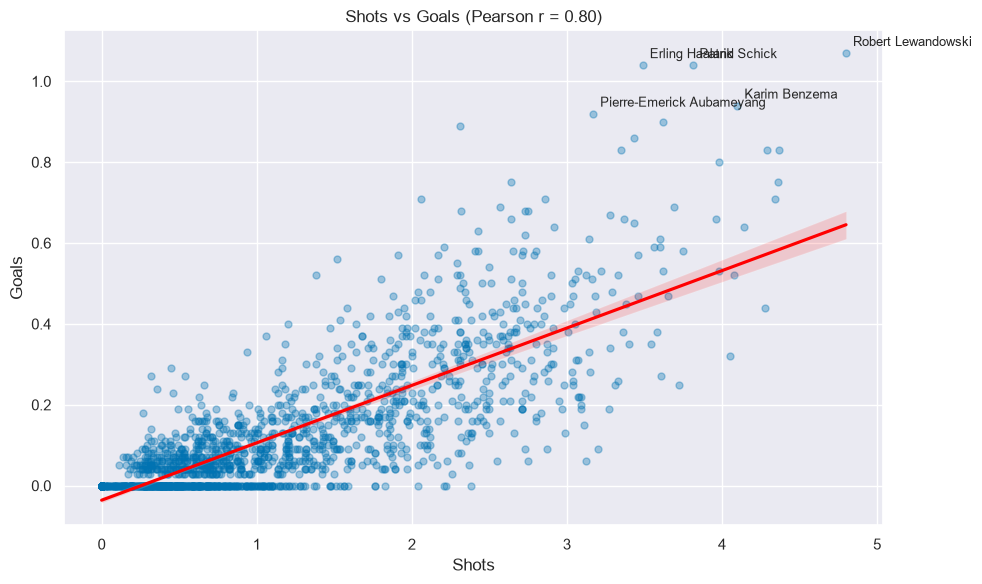


Conclusion 1:
Reject H0. Shots and goals have a strong positive link (r = 0.80, p < 0.05). Players who take more shots score more goals.


In [210]:
r, p_r = stats.pearsonr(df["Shots"], df["Goals"])
rho, p_s = stats.spearmanr(df["Shots"], df["Goals"])
print(f"Pearson  r   = {r:.3f}, p = {p_r:.2e}")
print(f"Spearman rho = {rho:.3f}, p = {p_s:.2e}")

plt.figure(figsize=(10, 6))
sns.regplot(data=df, x="Shots", y="Goals", scatter_kws={"alpha": 0.35, "s": 25},
            line_kws={"color": "red"})
top = df.nlargest(5, "Goals")
for _, row in top.iterrows():
    plt.annotate(row["Player"], (row["Shots"], row["Goals"]), xytext=(5, 5),
                 textcoords="offset points", fontsize=9)
plt.title(f"Shots vs Goals (Pearson r = {r:.2f})")
plt.tight_layout()
plt.show()

print("\nConclusion 1:")
if p_r < 0.05:
    print(f"Reject H0. Shots and goals have a strong positive link (r = {r:.2f}, p < 0.05). "
          "Players who take more shots score more goals.")
else:
    print("Fail to reject H0. We did not find a significant link between shots and goals.")

**Takeaway:** Shot volume is one of the strongest signals of goals, which matches common sense. Defensive stats like tackles and interceptions are weakly or negatively related to goals because the players who do them most are defenders, who rarely shoot. The heatmap also shows that some features (Shots and SoT) move together, so we should be careful about multicollinearity when we build models in the final deliverable.

## D. Analysis 2: Do positions score at different rates? (ANOVA)
**Method:** One-way ANOVA, backed up by the Kruskal-Wallis test and a Tukey post-hoc test.

**Question:** Is the average goals per 90 minutes different for forwards, midfielders, and defenders?

**H0:** All three positions have the same mean goals per 90.
**H1:** At least one position has a different mean.

We only use qualified players (900+ minutes) and skip goalkeepers.

In [211]:
pos_df = df[df["PrimaryPos"].isin(["FW", "MF", "DF"])]
groups = [g["Goals90"].values for _, g in pos_df.groupby("PrimaryPos")]

print(pos_df.groupby("PrimaryPos")["Goals90"].agg(["count", "mean", "median", "std"]).round(3))

f_stat, p_anova = stats.f_oneway(*groups)
h_stat, p_kw = stats.kruskal(*groups)
print(f"\nANOVA:          F = {f_stat:.2f}, p = {p_anova:.2e}")
print(f"Kruskal-Wallis: H = {h_stat:.2f}, p = {p_kw:.2e}")

KeyError: 'PrimaryPos'

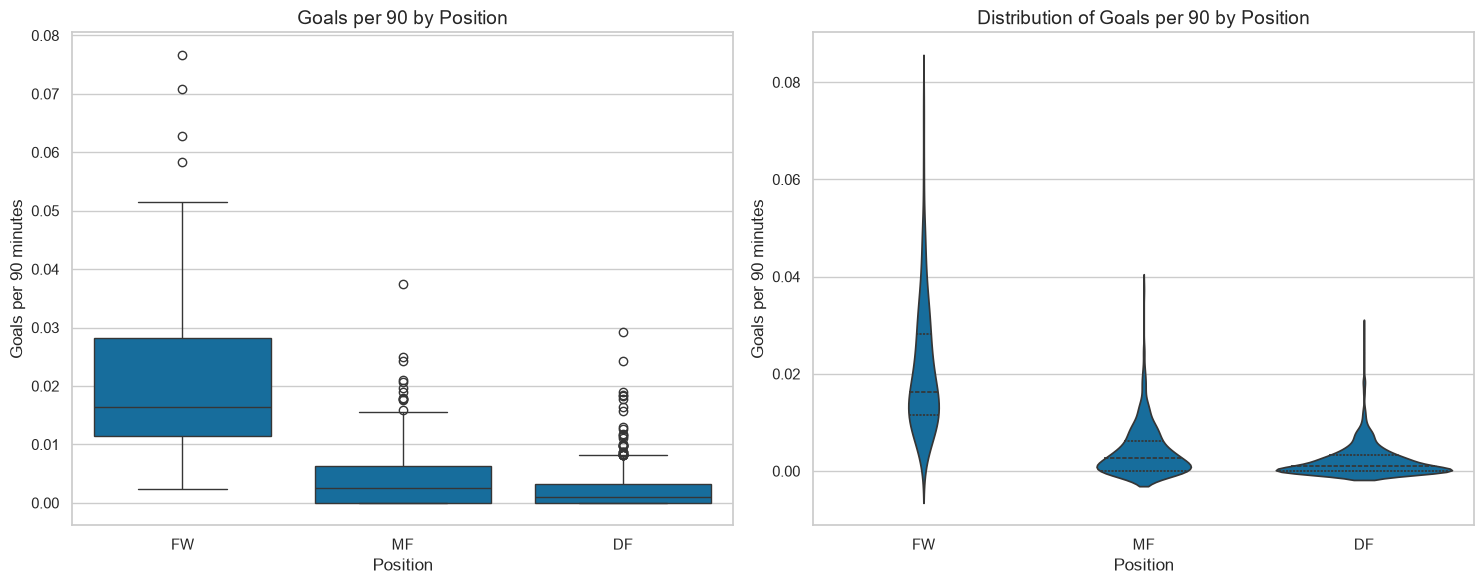

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
order = ["FW", "MF", "DF"]

sns.boxplot(data=pos_df, x="PrimaryPos", y="Goals90", order=order, ax=axes[0])
axes[0].set_title("Goals per 90 by Position")
axes[0].set_xlabel("Position")
axes[0].set_ylabel("Goals per 90 minutes")

sns.violinplot(data=pos_df, x="PrimaryPos", y="Goals90", order=order, inner="quartile", ax=axes[1])
axes[1].set_title("Distribution of Goals per 90 by Position")
axes[1].set_xlabel("Position")
axes[1].set_ylabel("Goals per 90 minutes")
plt.tight_layout()
plt.show()

In [ ]:
tukey = pairwise_tukeyhsd(endog=pos_df["Goals90"], groups=pos_df["PrimaryPos"], alpha=0.05)
print(tukey.summary())

print("\nConclusion 2:")
if p_anova < 0.05:
    print("Reject H0. Goals per 90 differ by position (ANOVA and Kruskal-Wallis agree). "
          "The Tukey test shows which pairs are different.")
else:
    print("Fail to reject H0. We did not find a significant difference between positions.")

Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj lower   upper  reject
--------------------------------------------------
    DF     FW   0.0186   0.0 0.0173  0.0198   True
    DF     MF   0.0019   0.0 0.0009  0.0029   True
    FW     MF  -0.0166   0.0 -0.018 -0.0153   True
--------------------------------------------------

Conclusion 2:
Reject H0. Goals per 90 differ by position (ANOVA and Kruskal-Wallis agree). The Tukey test shows which pairs are different.


**Takeaway:** Position is a major driver of scoring. Forwards score the most per 90 minutes, midfielders sit in the middle, and defenders score the least. Because of this, position should be a key feature (or a way to split the data) in any model we build later.

## E. Analysis 3: Young vs veteran players (Hypothesis test)
**Method:** Welch's two-sample t-test (does not assume equal variances), checked with the Mann-Whitney U test.

**Question:** Do players aged 23 and under produce a different number of goals plus assists per 90 minutes than players aged 30 and over?

**H0:** The two age groups have the same mean G+A per 90.
**H1:** The means are different.

We use qualified outfield players (900+ minutes, no goalkeepers).

In [ ]:
outfield = df[df["PrimaryPos"] != "GK"]
young = outfield[outfield["Age"] <= 23]["GA90"]
vets = outfield[outfield["Age"] >= 30]["GA90"]

print(f"Young (<=23): n = {len(young)}, mean = {young.mean():.3f}, median = {young.median():.3f}")
print(f"Veteran (>=30): n = {len(vets)}, mean = {vets.mean():.3f}, median = {vets.median():.3f}")

t_stat, p_t = stats.ttest_ind(young, vets, equal_var=False)
u_stat, p_u = stats.mannwhitneyu(young, vets, alternative="two-sided")

# Effect size (Cohen's d)
pooled = np.sqrt(((len(young)-1)*young.var() + (len(vets)-1)*vets.var()) / (len(young)+len(vets)-2))
d = (young.mean() - vets.mean()) / pooled

print(f"\nWelch t-test:   t = {t_stat:.3f}, p = {p_t:.4f}")
print(f"Mann-Whitney U: U = {u_stat:.0f}, p = {p_u:.4f}")
print(f"Cohen's d = {d:.3f}")

Young (<=23): n = 346, mean = 0.013, median = 0.008
Veteran (>=30): n = 391, mean = 0.012, median = 0.008

Welch t-test:   t = 0.370, p = 0.7118
Mann-Whitney U: U = 67694, p = 0.9859
Cohen's d = 0.027


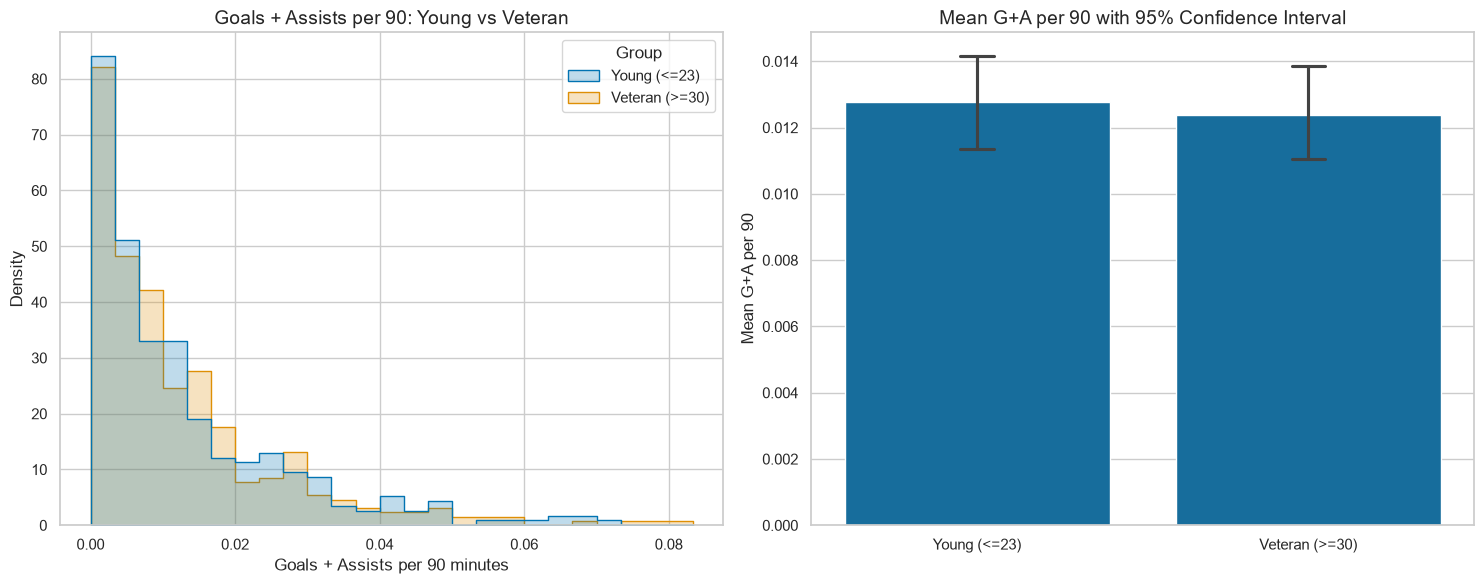

Conclusion 3:
Fail to reject H0 (p = 0.7118). We cannot say the two age groups differ in G+A per 90.


In [ ]:
age_df = pd.concat([
    pd.DataFrame({"Group": "Young (<=23)", "GA90": young}),
    pd.DataFrame({"Group": "Veteran (>=30)", "GA90": vets}),
])

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.histplot(data=age_df, x="GA90", hue="Group", bins=25, stat="density",
             common_norm=False, element="step", ax=axes[0])
axes[0].set_title("Goals + Assists per 90: Young vs Veteran")
axes[0].set_xlabel("Goals + Assists per 90 minutes")

sns.barplot(data=age_df, x="Group", y="GA90", errorbar=("ci", 95), capsize=0.1, ax=axes[1])
axes[1].set_title("Mean G+A per 90 with 95% Confidence Interval")
axes[1].set_xlabel("")
axes[1].set_ylabel("Mean G+A per 90")
plt.tight_layout()
plt.show()

print("Conclusion 3:")
if p_t < 0.05:
    higher = "younger" if young.mean() > vets.mean() else "veteran"
    print(f"Reject H0. The {higher} group produces more goals + assists per 90 (p = {p_t:.4f}).")
else:
    print(f"Fail to reject H0 (p = {p_t:.4f}). We cannot say the two age groups differ in G+A per 90.")